# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [1]:
# Twoje rozwiązanie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, validation_curve, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)

print(df.shape)
print(df.head())
print(df.describe())

(768, 9)
   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66              23       94  28.1   
4            0      137              40              35      168  43.1   

   pedigree  age  outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
       pregnancies     glucose  blood_pressure  skin_thickness     insulin  \
count   768.000000  768.000000      768.000000      768.000000  768.000000   
mean      3.845052  120.894531       69.105469       20.536458   79.799479   
std       3.369578   31.972618       19.355807       15.952218  115.244002   
min       0.000000    0.000000        0.000000        0.000000    

In [2]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

Czy są braki NaN:
pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64

Liczba zer w kolumnach:
pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome           500
dtype: int64


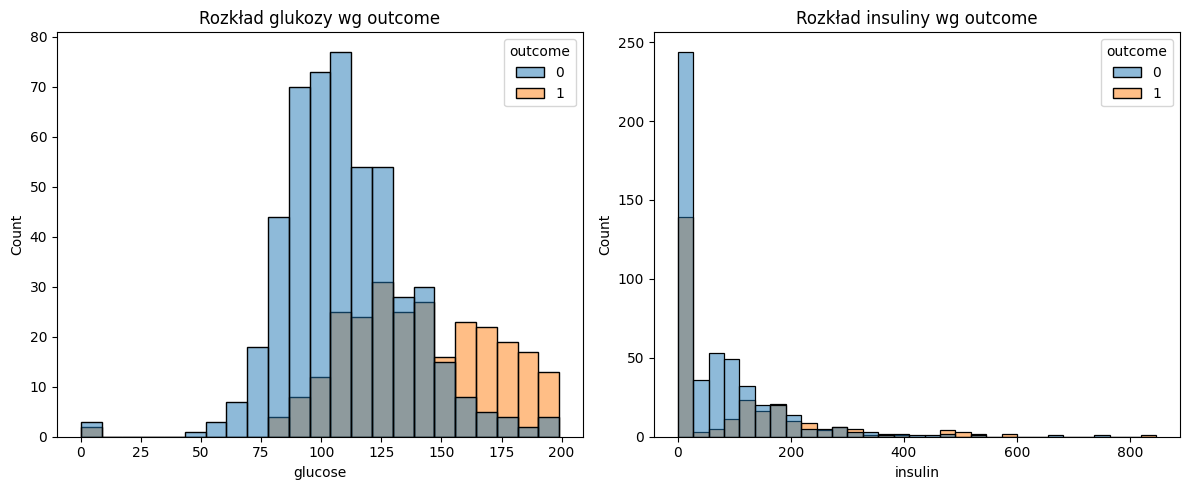

In [3]:
# Twoje rozwiązanie
class_share = df["outcome"].value_counts(normalize=True)

print("Czy są braki NaN:")
print(df.isna().sum())

zeros = (df == 0).sum()
print("\nLiczba zer w kolumnach:")
print(zeros)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0])
axes[0].set_title("Rozkład glukozy wg outcome")

sns.histplot(data=df, x="insulin", hue="outcome", ax=axes[1])
axes[1].set_title("Rozkład insuliny wg outcome")

fig.tight_layout()
plt.show()

In [4]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?


1 - Baseline osiągnie 65.1% accuracy.

2 - Niemożliwe jest dla podstawowych parametrów życiowych: glusoce, blood_pressure, skin_thickness, insulin oraz bmi. Zupełnie normalne jest dla pregnancies, wskazując na kobiety nie będące nigdy w ciąży.

3 - glucose. Na histogramie osoby z cukrzycą mają rozkład przesunięty w stronę wyższych stężeń glukozy w porównaniu do osób zdrowych.

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [5]:
# Twoje rozwiązanie
cols_zero = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
df_clean = df.copy()
df_clean[cols_zero] = df_clean[cols_zero].replace(0, np.nan)

missing = df_clean.isna().sum()
print("Liczba braków w df_clean:")
print(missing)

Liczba braków w df_clean:
pregnancies         0
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome             0
dtype: int64


In [6]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

Możliwe opcje to:

  - Usunięcie wierszy z brakami, ale odrzuciłoby to 374 z 768 pacjentek, co drastycznie zmniejszyłoby zbiór i zafałszowało próbę.

  - Całkowite wyrzucenie kolumny insulin – tracimy potencjalnie ważną cechę medyczną.

  - Imputacja pozwala zachować wszystkie pacjentki i wykorzystać pozostałe pomiary.

 Wybieram imputację medianą wewnątrz potoku. Pozwala to modelom uczyć się na pełnym zbiorze bez utraty danych z pozostałych badań.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [7]:
X = df_clean.drop(columns=["outcome"])
y = df_clean["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

def model_z(klasyfikator):
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        klasyfikator
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

                      CV średnia  CV odch.  train
model                                            
baseline                   0.651     0.002  0.651
regresja logistyczna       0.778     0.025  0.790
kNN                        0.736     0.021  0.835
drzewo decyzyjne           0.714     0.024  1.000
las losowy                 0.748     0.014  1.000


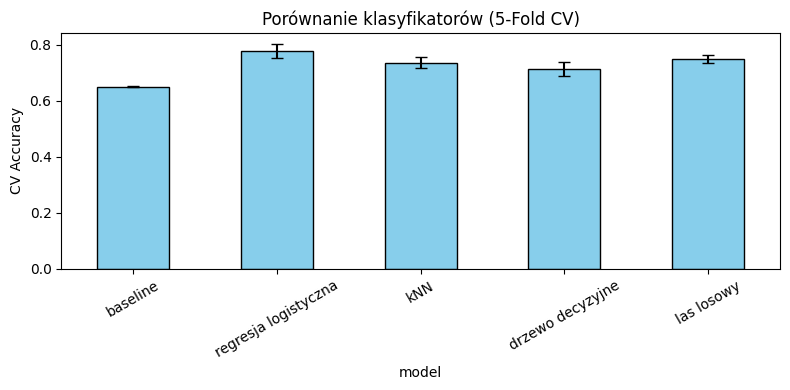

In [9]:
# Twoje rozwiązanie
modele = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresja logistyczna": LogisticRegression(random_state=42),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42)
}

rows = []
for name, clf in modele.items():
    pipe = model_z(clf)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv)
    pipe.fit(X_train, y_train)
    train_acc = pipe.score(X_train, y_train)
    rows.append({
        "model": name,
        "CV średnia": scores.mean(),
        "CV odch.": scores.std(),
        "train": train_acc
    })

porownanie = pd.DataFrame(rows).set_index("model")
print(porownanie.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
porownanie["CV średnia"].plot(
    kind="bar",
    yerr=porownanie["CV odch."],
    capsize=4,
    ax=ax,
    color="skyblue",
    edgecolor="black"
)
ax.set_ylabel("CV Accuracy")
ax.set_title("Porównanie klasyfikatorów (5-Fold CV)")
plt.xticks(rotation=30)
fig.tight_layout()
plt.show()

In [10]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

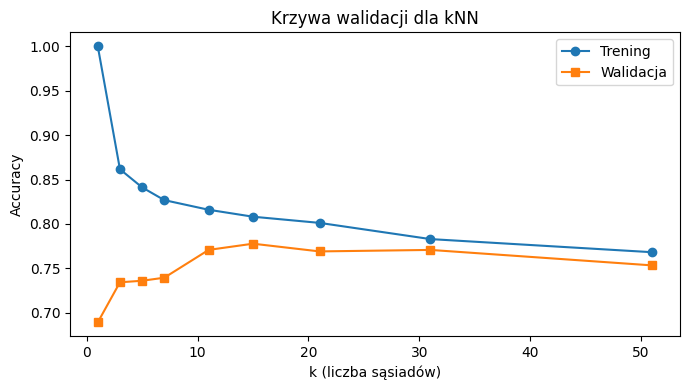

In [11]:
# Twoje rozwiązanie
ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]

tren, walid = validation_curve(
    model_z(KNeighborsClassifier()),
    X_train, y_train,
    param_name="kneighborsclassifier__n_neighbors",
    param_range=ks,
    cv=cv
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, tren.mean(axis=1), "o-", label="Trening")
ax.plot(ks, walid.mean(axis=1), "s-", label="Walidacja")
ax.set_xlabel("k (liczba sąsiadów)")
ax.set_ylabel("Accuracy")
ax.set_title("Krzywa walidacji dla kNN")
ax.legend()
fig.tight_layout()
plt.show()

In [12]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?


Wynik dla takiego treningu jest 1.0, bo przy jednym sąsiedzie każdy punkt zbioru treningowego jest swoim własnym najbliższym sąsiadem, więc model zwraca jego etykietę. Przeuczenie jest dla małych k, wynik treningu jest 1.0, a walidacji bardzo mocno spada. Niedouczenie jest dla dużych k, obie krzywe spadają w kierunku baseline.

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [13]:
# Twoje rozwiązanie
siatki = {
    "regresja logistyczna": (
        LogisticRegression(random_state=42),
        {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}
    ),
    "kNN": (
        KNeighborsClassifier(),
        {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}
    ),
    "drzewo decyzyjne": (
        DecisionTreeClassifier(random_state=42),
        {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}
    ),
    "las losowy": (
        RandomForestClassifier(random_state=42),
        {
            "randomforestclassifier__max_depth": [3, 5, 8, None],
            "randomforestclassifier__n_estimators": [100, 300]
        }
    )
}

wyniki_gs = {}
for name, (clf, grid) in siatki.items():
    gs = GridSearchCV(model_z(clf), grid, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs[name] = gs
    print(f"{name}: najlepsze parametry = {gs.best_params_}, CV score = {gs.best_score_:.3f}")

regresja logistyczna: najlepsze parametry = {'logisticregression__C': 1}, CV score = 0.778
kNN: najlepsze parametry = {'kneighborsclassifier__n_neighbors': 15}, CV score = 0.778
drzewo decyzyjne: najlepsze parametry = {'decisiontreeclassifier__max_depth': 5}, CV score = 0.750
las losowy: najlepsze parametry = {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 300}, CV score = 0.762


In [14]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

Wybrany model: regresja logistyczna
Accuracy na teście: 0.724



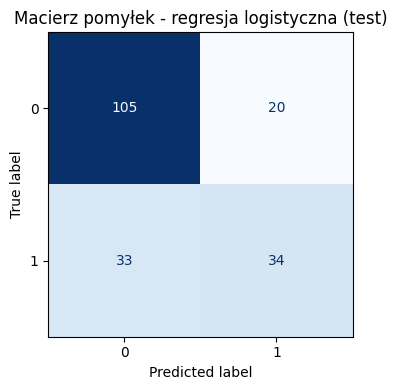


Raport klasyfikacji:
              precision    recall  f1-score   support

           0      0.761     0.840     0.798       125
           1      0.630     0.507     0.562        67

    accuracy                          0.724       192
   macro avg      0.695     0.674     0.680       192
weighted avg      0.715     0.724     0.716       192



In [15]:
# Twoje rozwiązanie
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_

acc_test = model_koncowy.score(X_test, y_test)
y_pred = model_koncowy.predict(X_test)

print(f"Wybrany model: {najlepszy}")
print(f"Accuracy na teście: {acc_test:.3f}\n")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(
    model_koncowy,
    X_test, y_test,
    ax=ax,
    cmap="Blues",
    colorbar=False
)
ax.set_title(f"Macierz pomyłek - {najlepszy} (test)")
fig.tight_layout()
plt.show()

print("\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred, digits=3))

In [16]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

1 - Wynik na teście jest zbliżony do średniej z walidacji krzyżowej. Różnica nie jest niepokojąca, w zbiorze testowym o rozmiarze 192 jedna osoba to 1/192 czyli ok. 0.52 p.p. To błąd losowy na poziomie 2-3 pacjentek.

2 - Recall wynosi ok. 55-60%. Dla pacjentek oznacza to, że 40% chorych kobiet zostanie przeoczone. Accuracy z kolei nie jest dobrą metryką, bo zbiór jest niezbalansowany i model zarówno może mieć wysoką trafność i mieć trudności z wykrywaniem chorych.

3 - Nie, przy takich różnicach w p.p. nie można wskazać jednoznacznie najlepszego modelu.Na innym losowym podziale danych na pierwszym miejscu równie dobrze mógłby znaleźć się las losowy zamiast regresji logistycznej.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [17]:
#1
gs_recall = GridSearchCV(
    model_z(LogisticRegression(random_state=42)),
    {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    cv=cv,
    scoring="recall"
)
gs_recall.fit(X_train, y_train)
print("Najlepsze C pod recall:", gs_recall.best_params_, "Recall CV:", gs_recall.best_score_)

#2
def model_flagi(clf):
    return make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        StandardScaler(),
        clf
    )

score_flagi = cross_val_score(model_flagi(LogisticRegression(random_state=42)), X_train, y_train, cv=cv).mean()
print("Średnia CV po dodaniu flag braków:", round(score_flagi, 3))

#3
X_raw = df.drop(columns=["outcome"])
y_raw = df["outcome"]
X_tr_raw, X_te_raw, y_tr_raw, y_te_raw = train_test_split(
    X_raw, y_raw, test_size=0.25, stratify=y_raw, random_state=42
)

model_raw = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))
score_raw = cross_val_score(model_raw, X_tr_raw, y_tr_raw, cv=cv).mean()
print("Średnia CV na surowych danych (z zerami):", round(score_raw, 3))

Najlepsze C pod recall: {'logisticregression__C': 1} Recall CV: 0.5825609756097561
Średnia CV po dodaniu flag braków: 0.767
Średnia CV na surowych danych (z zerami): 0.778
